# Interpreting the submission model with SHAP

**The model explained here** is the submitted one (`final_model_with_granite.ipynb`, `ml/final_model.py`): a 50/50 rank blend of
- **logistic regression (LR):** 12 features, and
- **LightGBM:** 16 features (200 trees of depth 2, averaged over 30 seeds),

both trained on the 2024 + 2025 backtest rows (64,120 CVEs, 85 later exploited) and used to rank the 72,670 CVEs of 2026.

**What SHAP is:** for one CVE, SHAP splits the model's output into one contribution per feature. The contributions add up exactly to the model's score minus its average score. A positive value pushed this CVE *up* the ranking, a negative value pushed it down. Averaging the size of the contributions over many CVEs gives a feature's **importance**; plotting them against the feature's value shows the **shape** of its effect; and SHAP *interaction values* split each contribution further into pairs of features.

**How it's computed here:**
- **LightGBM:** exact TreeSHAP (LightGBM's own `pred_contrib`), in log-odds, averaged over the 30 seed models. Interaction values use the `shap` package (`TreeExplainer`). Depth-2 trees can only combine two features at a time, so pairwise interactions describe everything the trees can do.
- **LR:** for a linear model, SHAP is exact and simple: weight × (standardized value − its training average).
- **The blend** combines the two models by *rank*, which isn't additive, so the two models are explained separately. LightGBM gets most of the attention because it's where non-linear effects and interactions can appear.

**What SHAP can't tell us:** it explains *the model*, not the world. A large SHAP value means the model relies on a feature to rank CVEs, not that the feature causes exploitation. Section 8 separates the two.

## 1. Rebuild the submission model (and check it's the same one)

In [1]:
import os, sys, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
ROOT = next(p for p in [Path(".."), Path(".")] if (p / "ml" / "config.py").exists()).resolve()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, lightgbm as lgb, shap
import matplotlib.pyplot as plt
from scipy.stats import rankdata, spearmanr
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score
from ml import config, data
from ml.featureset import FeatureBuilder
from ml.final_model import add_text_features

SMOKE = os.environ.get("SHAP_SMOKE") == "1"           # fast development run only
N_SEEDS = 3 if SMOKE else config.GBM_SEEDS
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e5e5e5", "grid.linewidth": 0.6, "axes.edgecolor": "#9a9a9a", "font.size": 9})
BLUE, ORANGE, GREY = "#2f6bd8", "#d9822b", "#8c8c8c"

con = data.connect()
tr_rows, va_rows = data.load_splits(con)
fb = FeatureBuilder(con)
import features as F
L = pd.concat([fb.transform(tr_rows).assign(year=2024), fb.transform(va_rows).assign(year=2025)], ignore_index=True).sort_values("cve_id", ignore_index=True)
sb = fb.transform(F.scoreboard_frame(con).sort_values("cve_id").reset_index(drop=True))
L = add_text_features(L, config.TEXT_SCORES_DIR / "text_oof_final.csv")
sb = add_text_features(sb, config.TEXT_SCORES_DIR / "text_2026.csv")
C_LR = config.TEAM_LR + config.GRANITE
C_GB = config.TEAM_LR + config.TEAM_GBM_EXTRA + config.GRANITE

def fit_models(D, seeds):
    lr = make_pipeline(StandardScaler(), LogisticRegression(C=config.LR_C, class_weight="balanced", max_iter=5000)).fit(D[C_LR], D.y)
    gbms = []
    for s in range(seeds):
        perm = np.random.default_rng(s).permutation(len(D))
        gbms.append(lgb.LGBMClassifier(**config.GBM_PARAMS, random_state=s).fit(D.iloc[perm][C_GB], D.iloc[perm].y))
    return lr, gbms

lr, gbms = fit_models(L, N_SEEDS)
p_lr = lr.predict_proba(sb[C_LR])[:, 1]
p_gb = np.mean([m.predict_proba(sb[C_GB])[:, 1] for m in gbms], axis=0)
sb["score"] = 0.5 * rankdata(p_lr) / len(sb) + 0.5 * rankdata(p_gb) / len(sb)
sb["rank"] = rankdata(-sb["score"], method="ordinal").astype(int)
top = sb.nsmallest(500, "rank")
submitted = pd.read_csv(ROOT / "outputs" / "top500.csv")
same = int(top.cve_id.isin(submitted.cve_id).sum())
print(f"training rows: {len(L):,} ({int(L.y.sum())} exploited) | 2026 scoreboard: {len(sb):,}")
print(f"LR {len(C_LR)} features, LightGBM {len(C_GB)} features, {N_SEEDS} seeds")
print(f"top 500 matches the submitted outputs/top500.csv: {same} of 500" + ("" if same == 500 else "  <-- NOT the submitted model"))
if not SMOKE:
    assert same == 500

training rows: 64,120 (85 exploited) | 2026 scoreboard: 72,670
LR 12 features, LightGBM 16 features, 30 seeds
top 500 matches the submitted outputs/top500.csv: 500 of 500


## 2. Compute SHAP values

For each of the 30 LightGBM models, TreeSHAP gives one contribution per feature per CVE (in log-odds), plus a base value. They're averaged over the models. **Check:** the contributions must add up exactly to each model's raw score.

One subtlety: the ensemble averages the models' *probabilities*, while averaged SHAP explains their average *log-odds*. The two rank CVEs almost identically (checked below), so the SHAP values describe the ranking the ensemble actually uses.

In [2]:
def gbm_contrib(X, models=gbms):
    return np.mean([m.booster_.predict(X, pred_contrib=True) for m in models], axis=0)
def lr_contrib(X):
    sc, clf = lr[0], lr[-1]
    return pd.DataFrame((sc.transform(X[C_LR]) - sc.transform(L[C_LR]).mean(0)) * clf.coef_[0], columns=C_LR, index=X.index)

raw_L = np.mean([m.booster_.predict(L[C_GB], raw_score=True) for m in gbms], axis=0)
SV_L, SV_S = gbm_contrib(L[C_GB]), gbm_contrib(sb[C_GB])
assert np.allclose(SV_L.sum(1), raw_L, atol=1e-6), "SHAP values don't add up"
phi = pd.DataFrame(SV_L[:, :-1], columns=C_GB)          # training rows
phi_s = pd.DataFrame(SV_S[:, :-1], columns=C_GB)        # 2026 scoreboard
lphi, lphi_s = lr_contrib(L), lr_contrib(sb)
prob_vs_logodds = spearmanr(np.mean([m.predict_proba(sb[C_GB])[:, 1] for m in gbms], axis=0), SV_S.sum(1)).correlation
print(f"SHAP values add up to the raw scores: yes (max error {np.abs(SV_L.sum(1) - raw_L).max():.1e})")
print(f"base value (average log-odds): {SV_L[0, -1]:.2f}")
print(f"rank agreement, averaged probabilities vs. averaged log-odds (2026): Spearman {prob_vs_logodds:.4f}")

SHAP values add up to the raw scores: yes (max error 5.3e-15)
base value (average log-odds): -5.64
rank agreement, averaged probabilities vs. averaged log-odds (2026): Spearman 0.9980


## 3. The most influential features

**Importance = average size of a feature's SHAP contribution** (mean |SHAP|, in log-odds). It's shown over all training CVEs, over the 85 exploited ones, and over the 2026 top 500 (what drives the picks we submitted).

Correlated features share credit. `any_exploit` and `poc_github` are almost the same column (Spearman 0.93), so the second table also sums features into **groups** before measuring importance.

,LightGBM: all CVEs,LightGBM: exploited,LightGBM: 2026 top 500,LR: all CVEs,LightGBM share,rank (LightGBM),rank (LR)
log_assigner_kev_rate,0.765,1.497,1.339,0.870,26.3%,1,1
log_batch_size,0.582,1.115,0.654,(GBM only),20.0%,2,(GBM only)
text_pct,0.451,0.988,0.911,0.531,15.5%,3,2
log_cwe_kev_rate,0.363,0.513,0.407,(GBM only),12.5%,4,(GBM only)
cvss_filled,0.347,0.542,0.536,0.378,11.9%,5,3
ui_none,0.115,0.136,0.143,0.253,3.9%,6,5
any_exploit,0.087,0.806,1.710,0.036,3.0%,7,11
kw_unauth,0.047,0.160,0.160,0.134,1.6%,8,6
product_has_kev,0.044,0.099,0.101,(GBM only),1.5%,9,(GBM only)
poc_github,0.028,0.256,0.608,0.060,1.0%,10,9


,all CVEs,exploited,2026 top 500,share (all CVEs)
issuer / product / weakness history,0.918207,2.008715,1.700941,37%
"release context (batch size, ID age)",0.584255,1.121794,0.654199,23%
Granite text score,0.450866,0.988373,0.911123,18%
"severity and reachability (CVSS, no login, no click, pre-auth, 'unauthenticated')",0.412507,0.806085,0.787411,16%
"exploit code (any_exploit, poc_github, nuclei)",0.116284,1.108808,2.341823,5%
"weakness type (auth, path traversal)",0.020276,0.066202,0.050568,1%


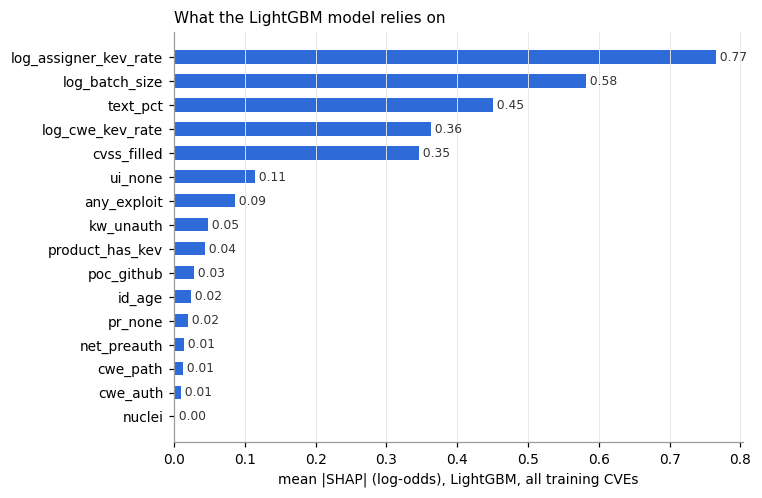

In [3]:
def is_binary(c): return set(pd.unique(L[c].dropna())) <= {0, 1}
pos, top_idx = L.y.to_numpy() == 1, top.index.to_numpy()
imp = pd.DataFrame({
    "LightGBM: all CVEs": phi.abs().mean(),
    "LightGBM: exploited": phi[pos].abs().mean(),
    "LightGBM: 2026 top 500": phi_s.loc[top_idx].abs().mean(),
    "LR: all CVEs": lphi.abs().mean(),
}).reindex(C_GB)
imp["LightGBM share"] = imp["LightGBM: all CVEs"] / imp["LightGBM: all CVEs"].sum()
imp["rank (LightGBM)"] = imp["LightGBM: all CVEs"].rank(ascending=False).astype(int)
imp["rank (LR)"] = imp["LR: all CVEs"].rank(ascending=False)
imp = imp.sort_values("LightGBM: all CVEs", ascending=False)
display(imp.style.format({c: "{:.3f}" for c in imp.columns[:4]} | {"LightGBM share": "{:.1%}", "rank (LR)": "{:.0f}"}, na_rep="(GBM only)"))

GROUPS = {"exploit code (any_exploit, poc_github, nuclei)": ["any_exploit", "poc_github", "nuclei"],
          "issuer / product / weakness history": ["log_assigner_kev_rate", "product_has_kev", "log_cwe_kev_rate"],
          "severity and reachability (CVSS, no login, no click, pre-auth, 'unauthenticated')": ["cvss_filled", "pr_none", "ui_none", "net_preauth", "kw_unauth"],
          "weakness type (auth, path traversal)": ["cwe_auth", "cwe_path"],
          "release context (batch size, ID age)": ["log_batch_size", "id_age"],
          "Granite text score": ["text_pct"]}
grp = pd.DataFrame({g: {"all CVEs": phi[c].sum(1).abs().mean(), "exploited": phi.loc[pos, c].sum(1).abs().mean(),
                        "2026 top 500": phi_s.loc[top_idx, c].sum(1).abs().mean()} for g, c in GROUPS.items()}).T
grp["share (all CVEs)"] = grp["all CVEs"] / grp["all CVEs"].sum()
display(grp.sort_values("all CVEs", ascending=False).style.format("{:.3f}").format({"share (all CVEs)": "{:.0%}"}))

fig, ax = plt.subplots(figsize=(7, 4.6))
s = imp["LightGBM: all CVEs"].iloc[::-1]
ax.barh(s.index, s.values, color=BLUE, height=0.55)
for y_, v in enumerate(s.values):
    ax.text(v, y_, f" {v:.2f}", va="center", fontsize=8, color="#333")
ax.set_xlabel("mean |SHAP| (log-odds), LightGBM, all training CVEs"); ax.set_title("What the LightGBM model relies on", loc="left", fontsize=10)
ax.grid(axis="y", visible=False); plt.tight_layout(); plt.show()

**Reading this:**
- **Five features do most of LightGBM's work:** the issuer's past KEV rate (26% of the total), release size (20%), the **Granite text score (16%)**, the weakness type's KEV rate (13%) and CVSS (12%). Together that's 86%. Logistic regression agrees on the order at the top: issuer history 1st, Granite text 2nd, CVSS 3rd.
- **Exploit code looks minor here (7th, 3%), but that's an averaging effect.** Only 2.2% of CVEs have public exploit code, so its average over *all* CVEs is small. Where it's present it's decisive: among the 85 exploited CVEs it averages 0.81. Among the 2026 top 500 it's the **largest single contribution (1.71)**, and the exploit-code group is the largest group (2.34). So there are two kinds of importance:
  - **Features that sort the whole population:** issuer history, release size and text.
  - **A rare feature that decides the top of the list:** exploit code.
- **The IBM Granite text score carries weight in the model:** 3rd in LightGBM, 2nd in LR, and 0.91 among the submitted 500.
- **At the bottom,** `cwe_auth`, `cwe_path`, `net_preauth`, `pr_none` and `nuclei` are each under 1%. Their information is mostly carried by other features (section 7).
- **The two models differ on `id_age`:** it's LR's 4th-largest input (a steady penalty for old IDs), while LightGBM barely uses it.

## 4. Direction of influence

For each feature: does a higher value push a CVE **up** (riskier) or **down**? It's measured three ways, side by side:
- **LightGBM:** for 0/1 features, the average SHAP when the feature is 1 minus when it's 0. For continuous features, the top tenth minus the bottom tenth. Shown as an **odds multiplier** (e^difference): "× 5" means the model's odds are about five times higher.
- **LR:** the sign and size of the weight (standardized inputs, other features held fixed).
- **The raw data:** the same comparison of observed exploitation rates (per 1,000), with no model involved.

In [4]:
def rate(mask): return 1000 * L.y[mask].mean() if mask.sum() else np.nan
rows = []
for c in C_GB:
    x = L[c]
    if is_binary(c):
        hi, lo, kind = x == 1, x == 0, "0/1"
    else:
        dec = pd.qcut(x.rank(method="first"), 10, labels=False); hi, lo, kind = dec == 9, dec == 0, "top vs. bottom tenth"
    d = phi.loc[hi, c].mean() - phi.loc[lo, c].mean()
    w = lr[-1].coef_[0][C_LR.index(c)] if c in C_LR else np.nan
    r_hi, r_lo = rate(hi), rate(lo)
    rows.append({"feature": c, "compared": kind, "share high": hi.mean(),
                 "LightGBM odds x": np.exp(d), "LR weight": w,
                 "observed per 1,000: high": r_hi, "observed per 1,000: low": r_lo,
                 "model direction": "up" if d > 0 else "down",
                 "data direction": "up" if r_hi > r_lo else "down" if r_hi < r_lo else "flat",
                 "Spearman(value, SHAP)": spearmanr(x, phi[c]).correlation})
direction = pd.DataFrame(rows).set_index("feature").loc[imp.index]
direction["LR agrees"] = np.where(direction["LR weight"].isna(), "(GBM only)",
                                  np.where(np.sign(direction["LR weight"]) == np.where(direction["model direction"] == "up", 1, -1), "yes", "NO"))
direction["data agrees"] = np.where(direction["model direction"] == direction["data direction"], "yes", "NO")
display(direction.style.format({"share high": "{:.1%}", "LightGBM odds x": "{:.2f}", "LR weight": "{:+.2f}",
                                "observed per 1,000: high": "{:.2f}", "observed per 1,000: low": "{:.2f}", "Spearman(value, SHAP)": "{:+.2f}"}, na_rep="-"))

,compared,share high,LightGBM odds x,LR weight,"observed per 1,000: high","observed per 1,000: low",model direction,data direction,"Spearman(value, SHAP)",LR agrees,data agrees
log_assigner_kev_rate,top vs. bottom tenth,10.0%,11.69,+1.06,6.08,0.00,up,up,+0.89,yes,yes
log_batch_size,top vs. bottom tenth,10.0%,0.06,-,0.16,6.39,down,down,-0.92,(GBM only),yes
text_pct,top vs. bottom tenth,10.0%,4.71,+0.61,7.02,0.16,up,up,+0.57,yes,yes
log_cwe_kev_rate,top vs. bottom tenth,10.0%,3.99,-,4.68,0.31,up,up,+0.70,(GBM only),yes
cvss_filled,top vs. bottom tenth,10.0%,2.27,+0.45,4.99,0.31,up,up,+0.77,yes,yes
ui_none,0/1,68.0%,1.30,+0.27,1.77,0.39,up,up,+0.81,yes,yes
any_exploit,0/1,2.2%,7.98,+0.12,24.39,0.81,up,up,+0.25,yes,yes
kw_unauth,0/1,7.6%,1.41,+0.25,6.38,0.91,up,up,+0.46,yes,yes
product_has_kev,0/1,5.8%,1.48,-,5.89,1.04,up,up,+0.41,(GBM only),yes
poc_github,0/1,1.9%,2.18,+0.22,24.88,0.87,up,up,+0.24,yes,yes


**Reading this:**
- **All 16 features push the score the same way the raw data does** ("data agrees" is yes for every row). The model learned no relationship backwards.
- **The largest effects,** as the model's odds multiplier (comparing values within each feature):

| Feature | Comparison | Odds multiplier |
|---|---|---|
| Issuer's past KEV rate | top vs. bottom tenth | **× 11.7** |
| Public exploit code | yes vs. no | **× 8.0** |
| Granite text score | top vs. bottom tenth | **× 4.7** |
| Weakness type's KEV rate | top vs. bottom tenth | **× 4.0** |
| CVSS | top vs. bottom tenth | **× 2.3** |
| Release size | largest vs. smallest tenth | **× 0.06**: the smallest releases carry about 17 times the odds |

- **One LR sign looks wrong but isn't.** `pr_none` (no privileges needed) gets a tiny negative LR weight (−0.05), though in the raw data such CVEs are 3 times riskier. LR weights are effects *with the other features held fixed*. Once "no click needed", "unauthenticated" wording and CVSS are known, "no privileges" adds nothing. The weight doesn't mean "no privileges" protects a CVE.

## 5. Non-linear relationships

A linear model can only say "more is better" at a constant rate. The trees can learn thresholds, plateaus and U-shapes. For each continuous feature:
- **Shape test:** how much of the SHAP variation a straight line explains (linear R²), against twenty bins (binned R²). A large gap means the effect isn't a straight line.
- **Dependence plots:** each dot is one CVE (a sample, plus every exploited CVE in orange). The black line is the binned average.
- **Decile tables:** the model's average contribution per tenth, beside the *observed* exploitation rate in that tenth. That's the direct comparison with the EDA's decile tables.

,linear R2,binned R2,non-linear part,monotonic? (Spearman of bin means)
feature,,,,
log_assigner_kev_rate,0.72,0.93,0.21,0.90
log_batch_size,0.72,0.95,0.23,-0.94
text_pct,0.50,0.89,0.39,0.56
log_cwe_kev_rate,0.54,0.96,0.42,0.70
cvss_filled,0.66,0.94,0.28,0.76
id_age,0.43,0.89,0.46,-0.73


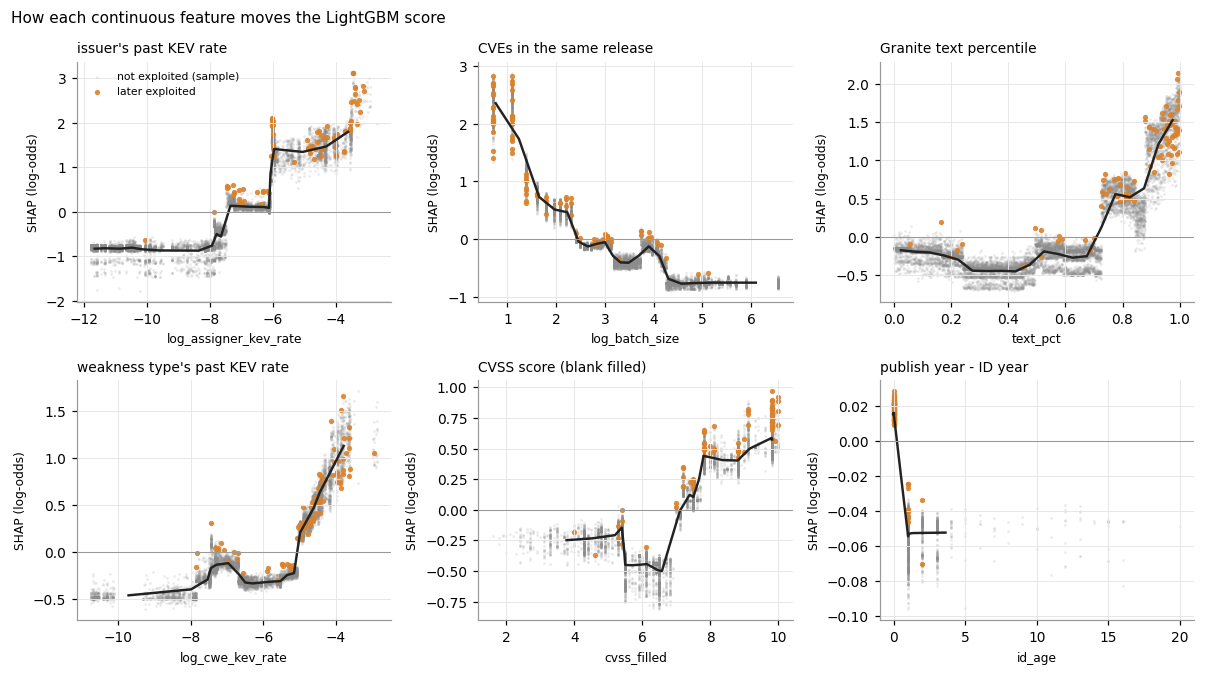

In [5]:
CONT = [c for c in imp.index if not is_binary(c)]
NATURAL = {"log_assigner_kev_rate": ("issuer's past KEV rate", lambda v: np.exp(v)),
           "log_batch_size": ("CVEs in the same release", lambda v: np.expm1(v)),
           "log_cwe_kev_rate": ("weakness type's past KEV rate", lambda v: np.exp(v)),
           "cvss_filled": ("CVSS score (blank filled)", lambda v: v), "text_pct": ("Granite text percentile", lambda v: v),
           "id_age": ("publish year - ID year", lambda v: v)}
shape = []
for c in CONT:
    x, s = L[c].to_numpy(float), phi[c].to_numpy()
    lin = np.corrcoef(x, s)[0, 1] ** 2
    b = pd.qcut(pd.Series(x).rank(method="first"), 20, labels=False)
    means = pd.Series(s).groupby(b).transform("mean")
    binned = 1 - ((s - means) ** 2).sum() / ((s - s.mean()) ** 2).sum()
    bm = pd.Series(s).groupby(b).mean()
    shape.append({"feature": c, "linear R2": lin, "binned R2": binned, "non-linear part": binned - lin,
                  "monotonic? (Spearman of bin means)": spearmanr(np.arange(len(bm)), bm).correlation})
display(pd.DataFrame(shape).set_index("feature").style.format("{:.2f}"))

rng = np.random.default_rng(0)
samp = np.union1d(rng.choice(len(L), min(12000, len(L)), replace=False), np.flatnonzero(pos))
fig, axes = plt.subplots(2, 3, figsize=(11, 6.2)); axes = axes.ravel()
for ax, c in zip(axes, CONT[:6]):
    name, nat = NATURAL.get(c, (c, lambda v: v))
    x, s = L[c].to_numpy(float), phi[c].to_numpy()
    neg_s = samp[~pos[samp]]
    ax.scatter(x[neg_s], s[neg_s], s=3, alpha=0.18, color=GREY, linewidths=0, label="not exploited (sample)")
    ax.scatter(x[pos], s[pos], s=12, alpha=0.9, color=ORANGE, linewidths=0, label="later exploited")
    b = pd.qcut(pd.Series(x).rank(method="first"), 20, labels=False)
    g = pd.DataFrame({"x": x, "s": s}).groupby(b).mean()
    ax.plot(g.x, g.s, color="#222", lw=1.6)
    ax.axhline(0, color="#999", lw=0.7)
    ax.set_title(name, loc="left", fontsize=9); ax.set_xlabel(c, fontsize=8); ax.set_ylabel("SHAP (log-odds)", fontsize=8)
axes[0].legend(fontsize=7, frameon=False, loc="upper left")
for ax in axes[len(CONT[:6]):]: ax.set_visible(False)
plt.suptitle("How each continuous feature moves the LightGBM score", x=0.01, ha="left", fontsize=10); plt.tight_layout(); plt.show()

In [6]:
def decile_table(c, q=10):
    name, nat = NATURAL.get(c, (c, lambda v: v))
    b = pd.qcut(L[c].rank(method="first"), q, labels=[f"D{i}" for i in range(1, q + 1)])
    g = pd.DataFrame({"v": nat(L[c]), "s": phi[c], "y": L.y}).groupby(b, observed=True)
    return pd.DataFrame({f"{name}: from": g.v.min(), "to": g.v.max(), "mean SHAP": g.s.mean(),
                         "odds x vs. average": np.exp(g.s.mean()), "exploited": g.y.sum(), "observed per 1,000": 1000 * g.y.mean()})
for c in [c for c in ["log_assigner_kev_rate", "log_batch_size", "cvss_filled", "text_pct", "log_cwe_kev_rate", "id_age"] if c in CONT]:
    fmt = {"mean SHAP": "{:+.2f}", "odds x vs. average": "{:.2f}", "observed per 1,000": "{:.2f}"}
    fmt.update({col: ("{:.4f}" if "rate" in col or col == "to" and c.startswith("log_") and "batch" not in c else "{:.2f}") for col in decile_table(c).columns[:2]})
    print(f"\n{c}"); display(decile_table(c).style.format(fmt))


log_assigner_kev_rate


,issuer's past KEV rate: from,to,mean SHAP,odds x vs. average,exploited,"observed per 1,000"
log_assigner_kev_rate,,,,,,
D1,0.0000,0.0000,-0.83,0.44,0,0.00
D2,0.0000,0.0000,-0.82,0.44,0,0.00
D3,0.0000,0.0001,-0.86,0.42,1,0.16
D4,0.0001,0.0004,-0.82,0.44,1,0.16
D5,0.0004,0.0005,-0.53,0.59,0,0.00
D6,0.0005,0.0009,+0.13,1.14,10,1.56
D7,0.0009,0.0022,+0.11,1.11,8,1.25
D8,0.0022,0.0024,+0.47,1.60,6,0.94
D9,0.0024,0.0109,+1.37,3.95,20,3.12



log_batch_size


,CVEs in the same release: from,to,mean SHAP,odds x vs. average,exploited,"observed per 1,000"
log_batch_size,,,,,,
D1,1.00,3.00,+2.04,7.72,41,6.39
D2,3.00,7.00,+0.62,1.87,10,1.56
D3,7.00,12.00,+0.21,1.24,9,1.40
D4,12.00,17.00,-0.10,0.90,3,0.47
D5,17.00,25.00,-0.17,0.85,8,1.25
D6,25.00,35.00,-0.40,0.67,1,0.16
D7,35.00,54.00,-0.20,0.82,7,1.09
D8,54.00,82.00,-0.49,0.61,4,0.62
D9,82.00,154.00,-0.76,0.47,1,0.16



cvss_filled


,CVSS score (blank filled): from,to,mean SHAP,odds x vs. average,exploited,"observed per 1,000"
cvss_filled,,,,,,
D1,0.00,4.80,-0.24,0.79,2,0.31
D2,4.80,5.40,-0.18,0.84,3,0.47
D3,5.40,5.50,-0.38,0.68,2,0.31
D4,5.50,6.30,-0.45,0.64,1,0.16
D5,6.30,7.00,-0.50,0.61,0,0.00
D6,7.00,7.50,+0.06,1.06,12,1.87
D7,7.50,7.80,+0.18,1.20,7,1.09
D8,7.80,8.80,+0.42,1.53,15,2.34
D9,8.80,9.80,+0.45,1.57,11,1.72


... (2 outputs left out)


log_cwe_kev_rate


,weakness type's past KEV rate: from,to,mean SHAP,odds x vs. average,exploited,"observed per 1,000"
log_cwe_kev_rate,,,,,,
D1,0.0000,0.0004,-0.42,0.65,2,0.31
D2,0.0004,0.0006,-0.23,0.80,1,0.16
D3,0.0006,0.0008,-0.14,0.87,3,0.47
D4,0.0008,0.0014,-0.17,0.84,6,0.94
D5,0.0014,0.0021,-0.32,0.72,1,0.16
D6,0.0021,0.0040,-0.31,0.73,3,0.47
D7,0.0040,0.0064,-0.23,0.79,9,1.40
D8,0.0064,0.0090,+0.26,1.30,16,2.50
D9,0.0090,0.0125,+0.55,1.74,14,2.18



id_age


,publish year - ID year: from,to,mean SHAP,odds x vs. average,exploited,"observed per 1,000"
id_age,,,,,,
D1,0.00,0.00,+0.02,1.02,8,1.25
D2,0.00,0.00,+0.02,1.02,8,1.25
D3,0.00,0.00,+0.02,1.02,9,1.40
D4,0.00,0.00,+0.02,1.02,10,1.56
D5,0.00,0.00,+0.02,1.02,13,2.03
D6,0.00,0.00,+0.02,1.02,10,1.56
D7,0.00,0.00,+0.02,1.02,9,1.40
D8,0.00,1.00,-0.00,1.00,7,1.09
D9,1.00,1.00,-0.05,0.95,4,0.62


**Reading this: no feature acts like a straight line.** Twenty bins explain 89-96% of each feature's SHAP variation, against 43-72% for a straight line.

- **Issuer history is a threshold.** The bottom half of CVEs (issuers with a KEV rate of about 0.05% or less) all get the same penalty (−0.83, odds × 0.44). The effect steps up at about 0.05% and 0.25%, reaching +1.63 (× 5.1) in the top tenth. This mirrors the raw data: **2 exploited in the bottom five tenths (32,060 CVEs), and 39 in the top tenth.**
- **Release size is a steep decay that then levels off.**
  - CVEs released alone or with 1-2 others: +2.04 (× 7.7).
  - About 12 per release: close to neutral.
  - Above about 80: a floor of −0.75.
  - Observed rates: 6.4 vs. 0.16 per 1,000.
- **The Granite text score is a hockey stick.** Below the 70th percentile it adds nothing (slightly negative). Above it, it climbs sharply to +1.37 (× 3.9) in the top tenth. **70 of the 85 exploited CVEs sit in the text score's top 30%.**
- **The weakness type's rate is a threshold** at about 0.6% (log rate ≈ −5.1). It's flat below that and rises steeply above it.
- **CVSS steps at 7.0:** negative below 7, positive above, then a plateau from 8 to 9.8 and a further boost at 9.8-10 (+0.58). That's the EDA's pattern (0.25 per 1,000 below 7).
  - *A dip to treat as noise:* scores of 5.5-7 are rated slightly below scores under 5.5. The data shows 1 exploited in 18,007 against 4 in 9,652, too few to trust. A quarter of the 5.5-7 band is cross-site scripting.
  - *By design:* blank scores are filled with 7.5, just above the step, so a blank counts as roughly neutral.
- **ID age is one small step at 1 year** (−0.05). LightGBM almost ignores it.

**Why this matters:** a linear model can't draw thresholds or hockey sticks. That's part of why the LightGBM half of the blend earns its place, even though logistic regression is competitive overall.

## 6. Feature interactions

SHAP interaction values split each feature's contribution into a **main effect** and a part that depends on **one other feature**. A pair's strength is the average size of that shared part. Depth-2 trees model only pairs, so this table covers every interaction the trees can express.

They're computed on a uniform sample of 20,000 training CVEs (for the population averages), plus every exploited CVE, over 10 of the 30 seed models (a sample of models; enough to rank the pairs).

In [7]:
N_INT_MODELS, N_INT_ROWS = (2, 2000) if SMOKE else (10, 20000)
uni = np.sort(np.random.default_rng(1).choice(len(L), N_INT_ROWS, replace=False))
rows_int = np.union1d(uni, np.flatnonzero(pos))
X_int = L.iloc[rows_int][C_GB]
IV = np.mean([shap.TreeExplainer(m.booster_).shap_interaction_values(X_int) for m in gbms[:N_INT_MODELS]], axis=0)
check = gbm_contrib(X_int, gbms[:N_INT_MODELS])[:, :-1]
print(f"interaction values add up to the SHAP values: max error {np.abs(IV.sum(2) - check).max():.1e}")
in_uni, in_pos = np.isin(rows_int, uni), pos[rows_int]
M, Mp = np.abs(IV[in_uni]).mean(0), np.abs(IV[in_pos]).mean(0)
pairs = pd.DataFrame([{"feature A": C_GB[i], "feature B": C_GB[j], "pair strength (all)": 2 * M[i, j], "pair strength (exploited)": 2 * Mp[i, j]}
                      for i in range(len(C_GB)) for j in range(i + 1, len(C_GB))]).sort_values("pair strength (all)", ascending=False, ignore_index=True)
main = pd.Series(np.diag(M), index=C_GB)
print(f"total main effects {main.sum():.3f} vs. total pair interactions {pairs['pair strength (all)'].sum():.3f} (mean |.| in log-odds)")
display(pairs.head(10).style.format({"pair strength (all)": "{:.4f}", "pair strength (exploited)": "{:.4f}"}))

interaction values add up to the SHAP values: max error 2.2e-15
total main effects 3.021 vs. total pair interactions 1.110 (mean |.| in log-odds)


,feature A,feature B,pair strength (all),pair strength (exploited)
0,log_assigner_kev_rate,text_pct,0.2806,0.3378
1,log_assigner_kev_rate,cvss_filled,0.1634,0.2479
2,cvss_filled,log_batch_size,0.0817,0.1797
3,log_assigner_kev_rate,log_batch_size,0.0816,0.2980
4,log_batch_size,text_pct,0.0743,0.2686
5,log_assigner_kev_rate,log_cwe_kev_rate,0.0608,0.1585
6,log_cwe_kev_rate,text_pct,0.0554,0.1288
7,cvss_filled,text_pct,0.0416,0.0833
8,ui_none,cvss_filled,0.0383,0.0325
9,log_assigner_kev_rate,ui_none,0.0262,0.0339


In [8]:
def cut(c, s):
    return (s == 1).map({True: "yes", False: "no"}) if is_binary(c) else pd.qcut(s.rank(method="first"), 3, labels=["low third", "middle third", "high third"])
def pair_table(a, b):
    i, j = C_GB.index(a), C_GB.index(b)
    D = L.iloc[rows_int][[a, b, "y"]].reset_index(drop=True).assign(inter=2 * IV[:, i, j])
    D = D[in_uni].reset_index(drop=True)
    A, B = cut(a, D[a]), cut(b, D[b])
    t = D.groupby([A.rename(a), B.rename(b)], observed=True).agg(CVEs=("y", "size"), exploited=("y", "sum"), interaction=("inter", "mean"))
    full = L.groupby([cut(a, L[a]).rename(a), cut(b, L[b]).rename(b)], observed=True).y.agg(["size", "sum", "mean"])
    t["observed per 1,000 (all rows)"] = 1000 * full["mean"]
    return t
for _, r in pairs.head(4).iterrows():
    print(f"\n{r['feature A']} x {r['feature B']}: the pair's joint contribution (log-odds), beyond each feature alone")
    display(pair_table(r["feature A"], r["feature B"]).style.format({"interaction": "{:+.3f}", "observed per 1,000 (all rows)": "{:.2f}"}))


log_assigner_kev_rate x text_pct: the pair's joint contribution (log-odds), beyond each feature alone



log_assigner_kev_rate x cvss_filled: the pair's joint contribution (log-odds), beyond each feature alone



cvss_filled x log_batch_size: the pair's joint contribution (log-odds), beyond each feature alone



log_assigner_kev_rate x log_batch_size: the pair's joint contribution (log-odds), beyond each feature alone


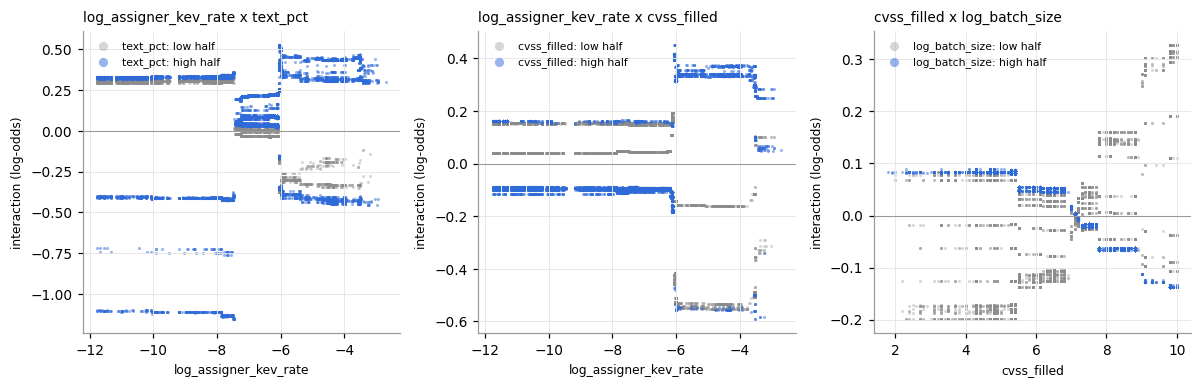

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, (_, r) in zip(axes, pairs.head(3).iterrows()):
    a, b = r["feature A"], r["feature B"]
    if is_binary(a) and not is_binary(b): a, b = b, a           # continuous feature on the x axis
    i, j = C_GB.index(a), C_GB.index(b)
    x, inter = X_int[a].to_numpy(float), 2 * IV[:, i, j]
    hi = (X_int[b] > X_int[b].median()).to_numpy() if not is_binary(b) else (X_int[b] == 1).to_numpy()
    jit = np.random.default_rng(0).normal(0, 0.03, len(x)) if is_binary(a) else 0
    ax.scatter(x[~hi] + (jit if np.ndim(jit) == 0 else jit[~hi]), inter[~hi], s=4, alpha=0.35, color=GREY, linewidths=0, label=f"{b}: {'0' if is_binary(b) else 'low half'}")
    ax.scatter(x[hi] + (jit if np.ndim(jit) == 0 else jit[hi]), inter[hi], s=4, alpha=0.5, color=BLUE, linewidths=0, label=f"{b}: {'1' if is_binary(b) else 'high half'}")
    ax.axhline(0, color="#999", lw=0.7); ax.set_xlabel(a, fontsize=8); ax.set_ylabel("interaction (log-odds)", fontsize=8)
    ax.set_title(f"{a} x {b}", loc="left", fontsize=9); ax.legend(fontsize=7, frameon=False, markerscale=3)
plt.tight_layout(); plt.show()

**Reading this:** interactions are about a quarter of the model's total effect (pairs 1.11 against main effects 3.02, in average log-odds). The model is mostly additive, with a few meaningful pairs.

1. **Issuer history × Granite text (the strongest pair, 0.28): text counts only when the issuer has a track record.**
   - Among the highest-history third of issuers, a high text score adds +0.25. Among the lowest-history third, it gets **−0.32**: the model discounts alarming descriptions from issuers whose products never reach KEV.
   - The data agrees: low-history issuers with high-text CVEs had **0.00 per 1,000** exploited, against **5.5 per 1,000** for high-history issuers with high-text CVEs.
2. **Issuer history × CVSS (0.16): the same pattern for severity.**
   - A high score adds +0.16 for high-history issuers (6.2 per 1,000 exploited) and −0.09 for low-history ones (0.2 per 1,000).
3. **CVSS × release size (0.08): a critical bug announced on its own is the riskiest combination.**
   - High CVSS in a small release: +0.16 (7.0 per 1,000).
   - High CVSS in a large release: −0.08 (0.8 per 1,000).
4. **Issuer history × release size: a correction, not a boost.**
   - High history and a small release get **−0.19**, even though this cell has one of the highest rates (6.5 per 1,000).
   - Both features point at the same thing, a big vendor's out-of-band advisory. Added together, their separate effects would overshoot, so the trees cut back to avoid counting it twice.

**The EDA's exploit code × issuer history pattern** (0 of 265 exploited when exploit code comes from a low-history issuer) **is learned in the same direction** (−0.25 for exploit code in the low-history third). It ranks only 14th of 120 pairs because exploit code is rare.

## 7. Compared with the original EDA

The EDA (`eda_report_evidence.ipynb`) measured each signal in the raw data, before any model. The checks below put the EDA's numbers next to what the model learned. Agreement means the model learned what's in the data. Disagreement is either the model adjusting for other features (good) or a learned artifact (to investigate).

In [10]:
def where(c): return direction.loc[c] if c in direction.index else None
def wp(col):   # SHAP of rows with a keyword the model has no feature for
    m = L[col] == 1 if col in L else pd.Series(False, index=L.index)
    return m.sum(), int(L.y[m].sum()), phi.loc[m, "text_pct"].mean(), phi.loc[m].sum(1).mean()
eda = []
eda.append(("Exploit code is the strongest single signal (rate ratio 30; within-issuer odds ratio 21)",
            f"rank {imp.loc['any_exploit','rank (LightGBM)']} alone; exploit-code group rank {list(grp.sort_values('all CVEs', ascending=False).index).index(list(GROUPS)[0]) + 1} of {len(GROUPS)}; odds x{direction.loc['any_exploit','LightGBM odds x']:.1f}"))
eda.append(("Issuer history has a threshold: 0-1 exploited per tenth in the bottom half, then rising to 6.1 per 1,000",
            f"rank {imp.loc['log_assigner_kev_rate','rank (LightGBM)']}; non-linear part {pd.DataFrame(shape).set_index('feature').loc['log_assigner_kev_rate','non-linear part']:.2f}"))
eda.append(("Small releases are riskier: lone CVEs 6.3 per 1,000 vs. 0.35 in batches of 51+",
            f"rank {imp.loc['log_batch_size','rank (LightGBM)']}; direction {direction.loc['log_batch_size','model direction']} (x{direction.loc['log_batch_size','LightGBM odds x']:.2f} top vs. bottom tenth)"))
eda.append(("CVSS is non-linear: 0.25 per 1,000 below 7, 15 at 9.9-10; 82% of 9+ scores are 9.8",
            f"rank {imp.loc['cvss_filled','rank (LightGBM)']}; non-linear part {pd.DataFrame(shape).set_index('feature').loc['cvss_filled','non-linear part']:.2f}"))
eda.append(("'Unauthenticated' wording: odds ratio 7.2 within issuer; network + no login + no click: 4.4; path traversal CWE: 5.0",
            "; ".join(f"{c} x{direction.loc[c,'LightGBM odds x']:.1f}" for c in ["kw_unauth", "net_preauth", "cwe_path"])))
eda.append(("Old IDs (reserved 2+ years earlier): 0.47 per 1,000 vs. 1.33 overall",
            f"id_age direction {direction.loc['id_age','model direction']}, rank {imp.loc['id_age','rank (LightGBM)']}"))
n, k, t, tot = wp("kw_wordpress")
eda.append(("WordPress: 0 of 6,232 exploited (no model feature for it)", f"{n:,} rows; text score SHAP {t:+.2f}, total LightGBM SHAP {tot:+.2f} (log-odds)"))
n, k, t, tot = wp("kw_xss")
eda.append(("Cross-site scripting: 2 of 10,450 (no model feature for it)", f"{n:,} rows; text score SHAP {t:+.2f}, total LightGBM SHAP {tot:+.2f}"))
eda.append(("Exploit code from a low-history issuer: 0 of 265 exploited (an interaction)",
            "see the any_exploit x log_assigner_kev_rate row of the interaction table" if ((pairs['feature A'] + pairs['feature B']).str.contains('any_exploit') & (pairs['feature A'] + pairs['feature B']).str.contains('assigner')).any() else "-"))
eda.append(("EPSS: top tenth 5.3 per 1,000, but a gap in Jan-Feb 2025 and AUC 0.50 in 2024", "EPSS is not a model input (team choice), so SHAP says nothing about it"))
pd.set_option("display.max_colwidth", 140)
pd.DataFrame(eda, columns=["EDA finding (raw data)", "What the model learned (SHAP)"])

,EDA finding (raw data),What the model learned (SHAP)
0,Exploit code is the strongest single signal (rate ratio 30; within-issuer odds ratio 21),rank 7 alone; exploit-code group rank 5 of 6; odds x8.0
1,"Issuer history has a threshold: 0-1 exploited per tenth in the bottom half, then rising to 6.1 per 1,000",rank 1; non-linear part 0.21
2,"Small releases are riskier: lone CVEs 6.3 per 1,000 vs. 0.35 in batches of 51+",rank 2; direction down (x0.06 top vs. bottom tenth)
3,"CVSS is non-linear: 0.25 per 1,000 below 7, 15 at 9.9-10; 82% of 9+ scores are 9.8",rank 5; non-linear part 0.28
4,'Unauthenticated' wording: odds ratio 7.2 within issuer; network + no login + no click: 4.4; path traversal CWE: 5.0,kw_unauth x1.4; net_preauth x1.0; cwe_path x1.3
5,"Old IDs (reserved 2+ years earlier): 0.47 per 1,000 vs. 1.33 overall","id_age direction down, rank 11"
6,"WordPress: 0 of 6,232 exploited (no model feature for it)","6,232 rows; text score SHAP -0.22, total LightGBM SHAP -1.28 (log-odds)"
7,"Cross-site scripting: 2 of 10,450 (no model feature for it)","10,450 rows; text score SHAP -0.20, total LightGBM SHAP -1.26"
8,Exploit code from a low-history issuer: 0 of 265 exploited (an interaction),see the any_exploit x log_assigner_kev_rate row of the interaction table
9,"EPSS: top tenth 5.3 per 1,000, but a gap in Jan-Feb 2025 and AUC 0.50 in 2024","EPSS is not a model input (team choice), so SHAP says nothing about it"


In [11]:
print("Where the model's penalty for WordPress and XSS CVEs comes from (mean LightGBM SHAP, log-odds; the model has no WordPress or XSS feature):")
wx = pd.DataFrame({name: phi[L[col] == 1].mean() for name, col in [("WordPress", "kw_wordpress"), ("XSS", "kw_xss")]} | {"all CVEs": phi.mean()})
display(wx.loc[wx[["WordPress", "XSS"]].abs().max(1).sort_values(ascending=False).index[:6]].style.format("{:+.2f}"))
ia = pairs[(pairs["feature A"] + "|" + pairs["feature B"]).str.contains("any_exploit") & (pairs["feature A"] + "|" + pairs["feature B"]).str.contains("log_assigner")]
print(f"any_exploit x log_assigner_kev_rate: pair rank {ia.index[0] + 1} of {len(pairs)}" if len(ia) else "pair not found")
display(pair_table("any_exploit", "log_assigner_kev_rate").style.format({"interaction": "{:+.3f}", "observed per 1,000 (all rows)": "{:.2f}"}))

Where the model's penalty for WordPress and XSS CVEs comes from (mean LightGBM SHAP, log-odds; the model has no WordPress or XSS feature):


,WordPress,XSS,all CVEs
log_assigner_kev_rate,-0.82,-0.35,-0.02
cvss_filled,-0.12,-0.24,-0.01
text_pct,-0.22,-0.20,+0.02
log_cwe_kev_rate,-0.13,-0.18,-0.01
ui_none,-0.03,-0.13,+0.00
log_batch_size,-0.01,-0.11,+0.00


any_exploit x log_assigner_kev_rate: pair rank 14 of 120


**Reading this: the model mostly confirms the EDA, shrinks three of its effects, and finds what the EDA couldn't.**

**Confirmed:**
- The issuer-history threshold, the small-release effect and the CVSS step at 7.
- That old IDs are less risky.
- The direction of every feature.
- That exploit code is decisive where present (it's the largest separator of the top 500).

**Smaller in the model than in the EDA (not contradictions):**
- **The effects:** "unauthenticated" wording drops from a within-issuer odds ratio of 7.2 to × 1.4 in the model. Network + no login + no click drops from 4.4 to × 1.04, and path traversal from 5.0 to × 1.3.
- **Why they shrink:** the EDA measured each signal alone, while the model sees them together and splits the credit.
  - Granite reads the same words.
  - A CVSS of 9.8 already encodes "network, no login".
  - The weakness type's KEV rate already covers path traversal.

**Learned without a feature for it:**
- **What the model does:** it has no WordPress or cross-site-scripting input, yet it pushes those CVEs down by about 1.3 log-odds (odds × 0.28). In the raw data they're 0 of 6,232 and 2 of 10,450 exploited.
- **Where the penalty comes from:** mostly **issuer history** (−0.82 for WordPress, because WordPress bugs are reported by plugin-focused issuers with almost no KEV history), then the Granite text (−0.22) and the weakness type's rate. The model penalizes *who reports* these bugs more than the word "WordPress".

**New compared with the EDA:**
- **The issuer × text and CVSS × release-size interactions.** The EDA's tables looked at one or two variables at a time and didn't test these pairs.
- **EPSS** can't be compared: it isn't a model input, by the team's choice. In the EDA it was unreliable: AUC 0.50 in 2024, and a data gap in early 2025.

## 8. Validating the findings

SHAP describes one fitted model. Before telling anyone "feature X matters", it should survive four checks:
1. **Seeds:** do the 30 LightGBM seeds agree on the ranking of features?
2. **Years:** fit on 2024 only and on 2025 only. Do the same features matter, in the same direction?
3. **Unseen data:** train on 2024, shuffle one feature (or one group) in 2025, and measure the drop in AUC and average precision. SHAP measures how much the model *uses* a feature. This measures whether that use *pays off* on new data. The text scores here are strictly forward: 2025 rows are scored by a text model that never saw a 2025 label.
4. **Weighed against noise:** five shuffles per feature, so the spread is visible.

In [12]:
seed_imp = pd.DataFrame([np.abs(m.booster_.predict(L[C_GB], pred_contrib=True)[:, :-1]).mean(0) for m in gbms], columns=C_GB)
rho = [spearmanr(seed_imp.iloc[i], imp.loc[C_GB, "LightGBM: all CVEs"]).correlation for i in range(len(seed_imp))]
top5 = imp.index[:5]
print(f"1. Seeds: Spearman of each seed's importance ranking with the average: median {np.median(rho):.2f}, lowest {np.min(rho):.2f}")
print("   share of seeds that put each of the top 5 features in their own top 5:",
      {c: f"{np.mean([c in seed_imp.iloc[i].nlargest(5).index for i in range(len(seed_imp))]):.0%}" for c in top5})

yr = {}
for year in [2024, 2025]:
    D = L[L.year == year].reset_index(drop=True)
    _, g = fit_models(D, min(10, N_SEEDS))
    ph = pd.DataFrame(gbm_contrib(D[C_GB], g)[:, :-1], columns=C_GB)
    dirn = {c: np.sign(ph.loc[D[c] == 1, c].mean() - ph.loc[D[c] == 0, c].mean()) if is_binary(c)
            else np.sign(spearmanr(D[c], ph[c]).correlation) for c in C_GB}
    yr[year] = pd.DataFrame({"importance": ph.abs().mean(), "direction": pd.Series(dirn)})
both = pd.concat({y: yr[y] for y in yr}, axis=1)
both["same direction"] = np.where(both[(2024, "direction")] == both[(2025, "direction")], "yes", "NO")
print(f"\n2. Years: Spearman of importance rankings, 2024-only vs. 2025-only models: {spearmanr(both[(2024,'importance')], both[(2025,'importance')]).correlation:.2f}; "
      f"same direction for {(both['same direction'] == 'yes').sum()} of {len(C_GB)} features")
display(both.loc[imp.index].style.format({(2024, "importance"): "{:.3f}", (2025, "importance"): "{:.3f}", (2024, "direction"): "{:+.0f}", (2025, "direction"): "{:+.0f}"}))

1. Seeds: Spearman of each seed's importance ranking with the average: median 0.95, lowest 0.84
   share of seeds that put each of the top 5 features in their own top 5: {'log_assigner_kev_rate': '100%', 'log_batch_size': '100%', 'text_pct': '100%', 'log_cwe_kev_rate': '100%', 'cvss_filled': '100%'}



2. Years: Spearman of importance rankings, 2024-only vs. 2025-only models: 0.74; same direction for 15 of 16 features


In [13]:
# Strictly forward text scores: 2024 out-of-fold over 2018-2024, 2025 from a text model that saw no 2025 label.
tr = add_text_features(L[L.year == 2024].reset_index(drop=True), config.TEXT_SCORES_DIR / "text_oof_train.csv")
va = add_text_features(L[L.year == 2025].reset_index(drop=True), config.TEXT_SCORES_DIR / "text_val_2025.csv")
lr24, g24 = fit_models(tr, min(10, N_SEEDS))
def blend_score(V):
    a = lr24.predict_proba(V[C_LR])[:, 1]; b = np.mean([m.predict_proba(V[C_GB])[:, 1] for m in g24], axis=0)
    return 0.5 * rankdata(a) + 0.5 * rankdata(b)
base_s = blend_score(va); base_auc, base_ap = roc_auc_score(va.y, base_s), average_precision_score(va.y, base_s)
perm_rows = []
for name, cols in [(c, [c]) for c in C_GB] + [(f"GROUP: {g}", c) for g, c in GROUPS.items() if len(c) > 1]:
    d_auc, d_ap = [], []
    for r in range(5):
        V = va.copy(); idx = np.random.default_rng(100 + r).permutation(len(V))
        V[cols] = va[cols].to_numpy()[idx]                     # shuffle the group's columns together
        s = blend_score(V); d_auc.append(base_auc - roc_auc_score(va.y, s)); d_ap.append(base_ap - average_precision_score(va.y, s))
    perm_rows.append({"shuffled": name, "AUC drop": np.mean(d_auc), "AUC drop (min-max)": f"{min(d_auc):+.3f} to {max(d_auc):+.3f}",
                      "AP drop": np.mean(d_ap), "AP drop (min-max)": f"{min(d_ap):+.3f} to {max(d_ap):+.3f}",
                      "SHAP rank": imp.loc[name, "rank (LightGBM)"] if name in imp.index else "-"})
perm = pd.DataFrame(perm_rows).set_index("shuffled").sort_values("AP drop", ascending=False)
print(f"3. Train 2024 -> 2025 blend: AUC {base_auc:.3f}, average precision {base_ap:.3f} (52 exploited). Drops when a feature is shuffled:")
singles = perm[~perm.index.str.startswith("GROUP")]
print(f"   Spearman between SHAP importance and AP drop (single features): "
      f"{spearmanr(singles['SHAP rank'].astype(float), -singles['AP drop']).correlation:.2f}")
display(perm.style.format({"AUC drop": "{:+.3f}", "AP drop": "{:+.3f}"}))

3. Train 2024 -> 2025 blend: AUC 0.904, average precision 0.141 (52 exploited). Drops when a feature is shuffled:
   Spearman between SHAP importance and AP drop (single features): 0.26


,AUC drop,AUC drop (min-max),AP drop,AP drop (min-max),SHAP rank
shuffled,,,,,
"GROUP: exploit code (any_exploit, poc_github, nuclei)",+0.022,+0.020 to +0.023,+0.100,+0.082 to +0.108,-
GROUP: issuer / product / weakness history,+0.094,+0.082 to +0.105,+0.094,+0.058 to +0.114,-
log_assigner_kev_rate,+0.081,+0.070 to +0.091,+0.086,+0.030 to +0.111,1
"GROUP: severity and reachability (CVSS, no login, no click, pre-auth, 'unauthenticated')",+0.032,+0.018 to +0.053,+0.081,+0.067 to +0.117,-
cvss_filled,+0.030,+0.015 to +0.050,+0.061,+0.048 to +0.084,5
poc_github,+0.007,+0.006 to +0.008,+0.034,+0.029 to +0.049,10
nuclei,+0.002,+0.002 to +0.002,+0.032,+0.032 to +0.032,16
"GROUP: release context (batch size, ID age)",+0.044,+0.033 to +0.059,+0.018,+0.007 to +0.028,-
kw_unauth,+0.005,+0.001 to +0.009,+0.017,+0.001 to +0.024,8


**Reading this:**
1. **Stable across seeds.** The 30 seed models agree on the ranking of features (median Spearman 0.95, lowest 0.84). All 30 put the same five features in their top 5.
2. **Mostly stable across years.**
   - Models fit on 2024 alone and on 2025 alone agree on direction for 15 of 16 features. The exception, `net_preauth`, is tiny in both.
   - They agree on the four most important features, with a rank correlation of 0.74 overall.
   - Some features drift. CVSS, `id_age`, `product_has_kev` and "unauthenticated" wording matter much less in 2025 models than in 2024 models, while release size matters more. **Findings about drifting features deserve the least confidence.**
3. **What pays off on unseen data (train 2024, test 2025) differs from what the model uses.**
   - **The rank correlation between SHAP importance and the loss in average precision when shuffled is only 0.26.**
   - **The groups that matter most at the top of the list are exploit code** (average precision −0.100) **and history** (−0.094). After them come issuer history alone (−0.086), the severity group (−0.081) and CVSS (−0.061). Exploit code, 7th by SHAP, is jointly the most valuable for the top of the list.
   - **The Granite text score pays off modestly but consistently:** average precision −0.015 (every shuffle between −0.009 and −0.024) and AUC −0.009. That's measured with strictly forward text scores.
   - **Used but not paying off:**
     - The weakness type's KEV rate is 4th by SHAP, yet 2025 is slightly *better* without it (+0.003).
     - `product_has_kev` behaves the same way.
     - Release size (2nd by SHAP) helps the overall ranking (AUC −0.026) but not the very top (average precision −0.004).
     - These are the features to test next for removal.
4. **The caveat:** this is one year with 52 positives, so differences in average precision of about 0.01 are close to noise. The cross-validation checks in section 12 would give tighter answers.

## 9. Three CVEs from the submitted list, explained

SHAP's most useful output for a reader is a per-CVE explanation: *why is this CVE on the list?* Three picks from the 2026 top 500:
1. the **#1-ranked** CVE,
2. the highest-ranked CVE **without public exploit code** (the group the model finds hardest),
3. the pick where the **Granite text score** pushed hardest.

#1 overall: CVE-2026-2699, rank 1 | issuer security@progress.com | exploit code 1 | CVSS 9.8 | text percentile 0.93 | ID age 0 | release of 4
   Customer Managed ShareFile Storage Zones Controller (SZC) allows an unauthenticated attacker to access restricted configuration pages. This leads to changing system configuration and potential remote code execution.

best pick with no exploit code: CVE-2026-1340, rank 150 | issuer 3c1d8aa1-5a33-4ea4-8992-aadd6440af75 | exploit code 0 | CVSS 9.8 | text percentile 0.95 | ID age 0 | release of 1
   A code injection in Ivanti Endpoint Manager Mobile allowing attackers to achieve unauthenticated remote code execution.

text score pushed hardest: CVE-2026-88920, rank 472 | issuer security@apache.org | exploit code 0 | CVSS 9.8 | text percentile 1.00 | ID age 0 | release of 19
   An authentication bypass in the DOM security processor in Apache WSS4J allows unauthenticated remote attackers to forge authenticated SOAP messages via a crafted unsigned SA

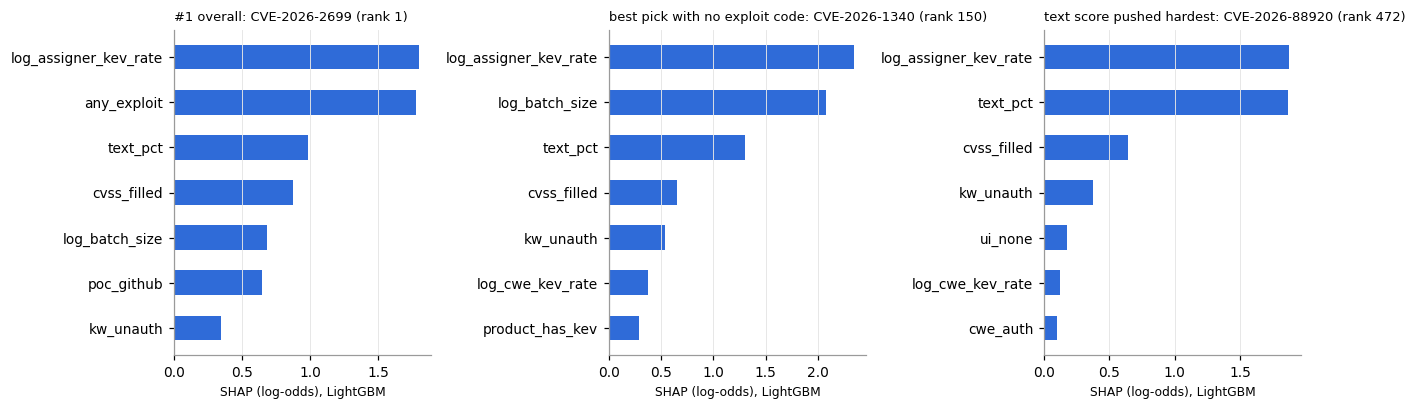

In [14]:
T = sb.loc[top_idx]
cases = {"#1 overall": T["rank"].idxmin(),
         "best pick with no exploit code": T[T.any_exploit == 0]["rank"].idxmin() if (T.any_exploit == 0).any() else T["rank"].idxmin(),
         "text score pushed hardest": phi_s.loc[top_idx, "text_pct"].idxmax()}
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (label, i) in zip(axes, cases.items()):
    r = sb.loc[i]; c = phi_s.loc[i].sort_values(key=np.abs, ascending=False).head(7).iloc[::-1]
    ax.barh(c.index, c.values, color=[BLUE if v > 0 else GREY for v in c.values], height=0.55)
    ax.axvline(0, color="#999", lw=0.7); ax.grid(axis="y", visible=False)
    ax.set_title(f"{label}: {r.cve_id} (rank {r['rank']})", loc="left", fontsize=8.5); ax.set_xlabel("SHAP (log-odds), LightGBM", fontsize=8)
    print(f"{label}: {r.cve_id}, rank {r['rank']} | issuer {r.assigner} | exploit code {int(r.any_exploit)} | CVSS {r.cvss3_score} | "
          f"text percentile {r.text_pct:.2f} | ID age {int(r.id_age)} | release of {int(round(np.expm1(r.log_batch_size)))}\n   {str(r.description)[:260]}\n")
plt.tight_layout(); plt.show()

In [15]:
print("What separates the 2026 top 500 from the rest of the scoreboard (mean LightGBM SHAP, log-odds):")
d = pd.DataFrame({"top 500": phi_s.loc[top_idx].mean(), "rest of 2026": phi_s.drop(index=top_idx).mean()})
d["difference"] = d["top 500"] - d["rest of 2026"]
display(d.sort_values("difference", ascending=False).style.format("{:+.3f}"))
out = ROOT / "outputs" / "shap"; out.mkdir(parents=True, exist_ok=True)
imp.to_csv(out / "feature_importance.csv")
pairs.to_csv(out / "interaction_pairs.csv", index=False)
(phi_s.loc[top_idx].add_prefix("shap_").assign(cve_id=sb.loc[top_idx, "cve_id"].values, rank=sb.loc[top_idx, "rank"].values)
 .sort_values("rank").to_csv(out / "top500_contributions.csv", index=False))
print("saved:", sorted(p.name for p in out.iterdir()), "(top500_contributions.csv = why each submitted CVE is on the list, for the demo)")

What separates the 2026 top 500 from the rest of the scoreboard (mean LightGBM SHAP, log-odds):


,top 500,rest of 2026,difference
any_exploit,+1.700,-0.009,+1.709
log_assigner_kev_rate,+1.334,+0.218,+1.115
text_pct,+0.835,+0.014,+0.821
poc_github,+0.604,-0.002,+0.606
log_batch_size,+0.341,-0.212,+0.553
cvss_filled,+0.498,+0.033,+0.465
log_cwe_kev_rate,+0.287,-0.032,+0.319
kw_unauth,+0.132,+0.023,+0.109
ui_none,+0.100,+0.002,+0.098
product_has_kev,+0.078,+0.035,+0.043


saved: ['feature_importance.csv', 'interaction_pairs.csv', 'top500_contributions.csv'] (top500_contributions.csv = why each submitted CVE is on the list, for the demo)


**Reading this:**
- **#1, CVE-2026-2699** (Progress ShareFile Storage Zones Controller: unauthenticated access to configuration, leading to possible remote code execution). Every signal points up:
  - the issuer's history (Progress, about +1.8)
  - public exploit code (about +1.75, plus +0.6 from a GitHub proof of concept)
  - the Granite text (+1.0)
  - CVSS 9.8
  - a release of only 4 CVEs
- **The best pick without exploit code, CVE-2026-1340** (Ivanti Endpoint Manager Mobile, unauthenticated code injection), at rank 150. With no exploit code yet, the model ranks it by *who, how it was announced, and what it says*:
  - Ivanti's KEV history (+2.3)
  - a lone release (+2.05)
  - text in the 95th percentile (+1.3)
- **The pick the text pushed hardest, CVE-2026-88920** (Apache WSS4J authentication bypass), at rank 472. The Granite text score (100th percentile, +1.85) contributes as much as Apache's history (+1.85). It's on the list by a narrow margin, which is the kind of case the text model was added to catch.
- **Across the whole submission,** the largest separators between the 500 picks and the rest of 2026 are exploit code (+1.71), issuer history (+1.12) and the Granite text score (+0.82).

`outputs/shap/top500_contributions.csv` holds this breakdown for every submitted CVE, ready for the demo ("why is this CVE on the list?").

## 10. Predictive importance is not causation

SHAP shows what the model **uses** to rank CVEs. It does not show what **causes** exploitation, for three general reasons:
- **The label is "CISA confirmed exploitation and added it to KEV",** not "attackers exploited it". Anything that makes exploitation easier to *detect or confirm* also predicts the label.
- **Correlated features share credit,** so a feature's SHAP depends on which other features are in the model (see `any_exploit` and `poc_github`).
- **These are observational data,** with no intervention.

| Feature | What the model found | Could it be causal? | Alternative explanations | What would test it |
|---|---|---|---|---|
| Public exploit code | × 8 odds; decides the top | **Partly plausible:** a public exploit lowers attackers' cost | Researchers write exploits for targets attackers already want (common cause). Public exploits also make attacks easier to *detect* and confirm (detection bias). | Compare CVEs in the same product and severity with and without exploit code. Check whether the exploit appeared *before* the first reported attack. |
| Issuer's KEV history | × 11.7; a threshold | **No:** a proxy | Stands in for product popularity, internet exposure, and attackers' and CISA's existing attention. Re-filing a bug under another issuer wouldn't change its risk. | Within-issuer analysis (as in the EDA). Compare with exploitation data not curated by CISA. |
| Small releases | lone releases × 7.7 | **No, and possibly reversed** | An urgent, standalone advisory is often a *response* to attacks already happening, so exploitation can cause the small release. Large batches are scheduled patch days and bulk audits. | Separate out-of-band advisories from scheduled ones. Check whether exploitation was known before the release. |
| Granite text score | × 4.7; hockey stick | **Partly:** it describes the bug class ("unauthenticated remote code execution" really is easier to exploit) | It also picks up vendors' writing styles and stock phrases, which are proxies for the issuer. | Counterfactual edits: remove or add key phrases and re-score. Check the text effect within issuer. |
| CVSS | step at 7 | **No:** a rating of the same properties that attract attackers | Who scores it changes between years (NIST vs. vendor), and 82% of 9+ scores are exactly 9.8. | Compare within issuer, by who scored it. |
| Weakness type's rate, product history | threshold / small | **No:** history proxies | Same as issuer history. | Same as issuer history. |
| Old IDs | small penalty | **No:** a selection effect | Old bugs re-filed years later are mostly archival (e.g. VulnCheck's legacy re-filings). | A breakdown by issuer. |

**How to say it:** *"CVEs with these characteristics have historically been far more likely to be added to KEV, and our model uses that pattern."* Not: *"these characteristics make a CVE exploited."* For prioritizing patches, prediction is what matters, because the goal is to fix what will be exploited, whatever the cause.

## 11. Three discoveries for the judges

**1. "Who and how it's announced" predicts exploitation better than "what the bug is."**
- **The claim:** the two most-used signals describe the *release*, not the bug.
  - **The issuer's track record:** half of all CVEs come from issuers below a threshold where almost nothing gets exploited (2 of 32,060).
  - **Whether the CVE was announced alone:** lone or tiny releases have 6.4 exploited per 1,000, against 0.16 for releases of 80+ (odds × 7.7 vs. average).
- **The interactions sharpen it:** a critical CVSS score matters when the bug is announced alone and comes from a vendor attackers already target, and is discounted otherwise.
- **Evidence:** SHAP sections 3 and 5-6. It's stable across all 30 seeds, and issuer history is the largest single loss on unseen 2025 data.

**2. IBM Granite reads something the numbers miss, and the model learned when to trust it.**
- **The claim:** the Granite text score (frozen `granite-embedding-small` embeddings with a logistic regression on top) is the **3rd-most-used input**, with a hockey-stick shape. Only the top 30% of text scores matter, and that 30% holds **70 of the 85** exploited CVEs.
- **The model learned when to trust it:** its strongest interaction is *issuer history × text*. Alarming descriptions count from vendors with a KEV history (5.5 per 1,000) and are discounted from vendors without one (0 per 1,000).
- **It pays off on new data:** shuffling the text score on unseen 2025 data lowers average precision in every repeat.
- **Evidence:** sections 3, 5, 6 and 8.

**3. Exploit code is rare but decisive, and averaging hides it.**
- **The claim:** public exploit code exists for only 2.2% of CVEs, so by the usual SHAP summary (average importance) it ranks just **7th**. Yet where it's present it multiplies the odds by 8. It's the **largest separator** between our 2026 top 500 and everything else, and shuffling the exploit-code features costs the most precision on unseen 2025 data.
- **The lesson for anyone reading SHAP charts:** *average importance is not decisive importance*.
- **The demo:** every submitted CVE comes with this kind of explanation (`outputs/shap/top500_contributions.csv`).
- **Evidence:** sections 3, 8 and 9.

*An alternative if one of these overlaps another team's story:* **the model learned to skip WordPress and cross-site-scripting bugs without being told** (−1.3 log-odds; 0 of 6,232 WordPress CVEs were exploited). It did this mostly through *who reports them*, which also shows that issuer history works as a proxy (section 7).

## 12. Further analyses to validate these findings

Ordered by value for effort:
1. **Group importance under cross-validation** (85 positives, 5 repeats), not one year. Shuffle or drop each feature group inside the existing cross-validation and report intervals. This tightens section 8's single-year numbers.
2. **A pre-registered removal test** for the features the model uses but that don't pay off: the weakness type's KEV rate and `product_has_kev`. Use the same rules as experiment 1 (forward and cross-validation, paired bootstrap).
3. **Bootstrap SHAP:** refit on resampled training sets to get intervals for each feature's importance and for the threshold locations (issuer rate about 0.05%, CVSS 7, text 70th percentile).
4. **Confirm the interactions directly:**
   - Rate tables with exact intervals for the issuer × text and CVSS × release-size cells.
   - An LR with those two product terms added, tested in cross-validation.
5. **Time stability:** compute SHAP for each origin's model in the rolling-origin test (`exp2`). That shows whether the thresholds and rankings hold month to month, not just across two years.
6. **Text counterfactuals:** remove or insert key phrases ("unauthenticated", "remote code execution", product names) and re-score with Granite. That shows *which words* drive the text score and whether it's reading the bug or the vendor.
7. **Probing causality for exploit code:**
   - Matched comparisons within issuer and severity.
   - A check of whether the public exploit predates the KEV date.
8. **Label bias:** compare against exploitation evidence that isn't CISA's KEV (other exploited-vulnerability catalogs, honeypot data). That shows whether issuer history predicts *exploitation* or *CISA's attention*.